# M4 + M5: Testing the hypothesis — Flatten vs. Global Average Pooling
**Team:** Kalash kumari Thakur · Dally
**Base paper:** Wong et al. (2025), *PLoS ONE* 20(5): e0322624

**Hypothesis (M3):** replacing the Flatten layer with Global Average Pooling (GAP) will reduce overfitting. The head shrinks from 6.4 M to 0.13 M weights.

**Predictions (written before running):**

| Measure | Prediction |
|---|---|
| Test accuracy | +1 to +3 points |
| Validation loss | 30–60 % lower |
| Train–validation loss gap | smaller |
| Glioma recall | higher (weakest class) |
| Pituitary recall | **risk:** may dip, because GAP discards location |
| Macro AUC | slightly higher |

**What this notebook does:** it trains both models with *identical* data, augmentation, schedule and seed. Only the head differs. It then produces:
- **M4:** the ablation table and an automatic check of each prediction.
- **M5:** confusion matrices, misclassified images, Grad-CAM heatmaps and the duplicate-leakage analysis.

**How to run on Kaggle:**
1. Attach the brain-tumor dataset (and `keras-pretrained-models` if the internet is off).
2. Set the GPU accelerator.
3. Click **Save Version → Save & Run All**. It runs in the background, about 2–2.5 h on a T4.
4. Download `work/results/` from the **Output** tab.

In [1]:
# Install tf_keras only if missing (Keras 2 API, as used by the paper)
import importlib.util, subprocess, sys
if importlib.util.find_spec("tf_keras") is None:
    import tensorflow as _tf
    _v = ".".join(_tf.__version__.split(".")[:2])
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"tf_keras=={_v}.*"], check=False)

In [2]:
import os, random, math, shutil, json, glob, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
try:
    import tf_keras as keras
except ImportError:
    from tensorflow import keras
_img = keras.preprocessing.image
ImageDataGenerator, load_img, img_to_array, array_to_img = (
    _img.ImageDataGenerator, _img.load_img, _img.img_to_array, _img.array_to_img)
VGG16 = keras.applications.VGG16
layers, models, optimizers, callbacks = keras.layers, keras.models, keras.optimizers, keras.callbacks
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, log_loss
print("TF", tf.__version__, "| Keras", keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TF 2.20.0 | Keras 2.20.1 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Configuration

In [3]:
SEED = 42
DATA_ROOT = "/kaggle/input" if os.path.exists("/kaggle/input") else None   # None -> kagglehub download
WORK_DIR = Path("work"); RES = WORK_DIR / "results"

HEADS = ["flatten", "gap"]        # baseline first, then the hypothesis (one variable changed)

IMG_SIZE = (224, 224); BATCH_SIZE = 32
N_AUG_PER_IMAGE = 2; SHEAR_RANGE = 0.2; ZOOM_RANGE = 0.2
WEIGHTS = "imagenet"
LR_STAGE1, LR_STAGE2 = 1e-3, 1e-4
EPOCHS_STAGE1, EPOCHS_STAGE2 = 50, 50
N_FROZEN_STAGE2 = 10
STEPS_PER_EPOCH = 179; VALIDATION_STEPS = 21   # paper settings

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
NAMES = ["glioma tumor", "meningioma tumor", "no tumor", "pituitary tumor"]
RES.mkdir(parents=True, exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s); os.environ["PYTHONHASHSEED"] = str(s)
set_seed()

## 2. Data (same pipeline as M2)

In [4]:
# VGG16 weights offline (Kaggle without internet): copy from an attached dataset if present
found = glob.glob("/kaggle/input/**/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5", recursive=True)
if found:
    dest = Path.home() / ".keras" / "models"; dest.mkdir(parents=True, exist_ok=True)
    shutil.copy(found[0], dest); print("VGG16 weights from", found[0])

if DATA_ROOT is None:
    import kagglehub
    DATA_ROOT = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

def find_dir(root, name):
    for dirpath, dirnames, _ in os.walk(root):
        if name in dirnames: return Path(dirpath) / name
    raise FileNotFoundError(f"{name}/ not found under {root}")
RAW_TRAIN, RAW_TEST = find_dir(DATA_ROOT, "Training"), find_dir(DATA_ROOT, "Testing")
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
def list_images(d): return sorted(p for p in Path(d).iterdir() if p.suffix.lower() in IMG_EXT)

PROC = WORK_DIR / "data"; TRAIN_DIR, VAL_DIR, TEST_DIR = PROC/"train", PROC/"val", PROC/"test"
offline_aug = ImageDataGenerator(shear_range=SHEAR_RANGE, zoom_range=ZOOM_RANGE, horizontal_flip=True, fill_mode="nearest")
def to_gray_array(p): return img_to_array(load_img(p, color_mode="grayscale", target_size=IMG_SIZE))
def save_png(a, p): array_to_img(a, scale=False).save(p)

if PROC.exists(): shutil.rmtree(PROC)
rng = random.Random(SEED)
for c in CLASSES:
    (TRAIN_DIR/c).mkdir(parents=True, exist_ok=True)
    for p in list_images(RAW_TRAIN/c):
        x = to_gray_array(p); save_png(x, TRAIN_DIR/c/f"{p.stem}.png")
        for k in range(N_AUG_PER_IMAGE):
            save_png(offline_aug.random_transform(x), TRAIN_DIR/c/f"{p.stem}_aug{k}.png")
    files = list_images(RAW_TEST/c); rng.shuffle(files); n_val = math.ceil(len(files)/2)
    for d, subset in [(VAL_DIR, files[:n_val]), (TEST_DIR, files[n_val:])]:
        (d/c).mkdir(parents=True, exist_ok=True)
        for p in subset: save_png(to_gray_array(p), d/c/f"{p.stem}.png")

counts = pd.DataFrame({s: {c: len(list((d/c).glob("*.png"))) for c in CLASSES}
                       for s, d in [("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR)]})
counts.loc["TOTAL"] = counts.sum(); counts

VGG16 weights from /kaggle/input/datasets/gaborfodor/keras-pretrained-models/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5


,train,val,test
glioma,4200,200,200
meningioma,4200,200,200
notumor,4200,200,200
pituitary,4200,200,200
TOTAL,16800,800,800


In [5]:
eval_datagen = ImageDataGenerator(rescale=1/255)
common = dict(target_size=IMG_SIZE, color_mode="rgb", batch_size=BATCH_SIZE, class_mode="categorical", classes=CLASSES)
def make_gens():
    tr = ImageDataGenerator(rescale=1/255).flow_from_directory(TRAIN_DIR, shuffle=True, seed=SEED, **common)
    va = eval_datagen.flow_from_directory(VAL_DIR, shuffle=False, **common)
    te = eval_datagen.flow_from_directory(TEST_DIR, shuffle=False, **common)
    return tr, va, te

# Duplicate audit: which test images have an identical fingerprint (dHash) in Training/?
def dhash(path, size=8):
    a = np.asarray(Image.open(path).convert("L").resize((size+1, size), Image.BILINEAR), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten().tobytes()
train_hashes = {dhash(p) for c in CLASSES for p in list_images(RAW_TRAIN/c)}
raw_test = {(c, p.stem): p for c in CLASSES for p in list_images(RAW_TEST/c)}
_, _, _te = make_gens()
DUP = np.array([dhash(raw_test[(Path(f).parent.name, Path(f).stem)]) in train_hashes for f in _te.filenames])
print(f"Test images matching a training image: {DUP.sum()} / {len(DUP)}")

Found 16800 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
Test images matching a training image: 202 / 800


## 3. Models: identical except for the head

In [6]:
def build_model(head):
    base = VGG16(weights=WEIGHTS, include_top=False, input_shape=IMG_SIZE + (3,))
    base.trainable = False
    pool = layers.Flatten(name="flatten") if head == "flatten" else layers.GlobalAveragePooling2D(name="gap")
    model = models.Sequential([base, pool,
                               layers.Dense(256, activation="relu", name="dense"),
                               layers.Dense(len(CLASSES), activation="softmax", name="output")], name=f"vgg16_{head}")
    return model, base

for h in HEADS:
    m, _ = build_model(h)
    head_params = sum(int(np.prod(w.shape)) for l in m.layers[1:] for w in l.trainable_weights)
    print(f"{h:8s} head trainable weights: {head_params:,}")
    del m
keras.backend.clear_session()

I0000 00:00:1793767132.210274      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793767132.214672      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


flatten  head trainable weights: 6,423,812
gap      head trainable weights: 132,356


## 4. Train both models (two-stage, paper schedule)

In [7]:
RUNS = {}
for head in HEADS:
    print(f"\n==================== {head.upper()} ====================")
    keras.backend.clear_session(); set_seed()
    train_gen, val_gen, test_gen = make_gens()
    model, base = build_model(head)
    model.compile(optimizer=optimizers.Adam(LR_STAGE1), loss="categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h1 = model.fit(train_gen, steps_per_epoch=STEPS_PER_EPOCH, epochs=EPOCHS_STAGE1,
                   validation_data=val_gen, validation_steps=VALIDATION_STEPS, verbose=2)
    base.trainable = True
    for l in base.layers[:N_FROZEN_STAGE2]: l.trainable = False
    model.compile(optimizer=optimizers.Adam(LR_STAGE2), loss="categorical_crossentropy", metrics=["accuracy"])
    n1 = len(h1.history["loss"])
    h2 = model.fit(train_gen, steps_per_epoch=STEPS_PER_EPOCH, epochs=n1 + EPOCHS_STAGE2, initial_epoch=n1,
                   validation_data=val_gen, validation_steps=VALIDATION_STEPS, verbose=2)
    hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
    model.save(RES / f"model_{head}.keras")
    pd.DataFrame(hist).to_csv(RES / f"history_{head}.csv", index=False)

    val_gen.reset(); test_gen.reset()
    val_probs = model.predict(val_gen, steps=math.ceil(val_gen.samples / BATCH_SIZE), verbose=0)
    test_probs = model.predict(test_gen, steps=math.ceil(test_gen.samples / BATCH_SIZE), verbose=0)
    RUNS[head] = dict(hist=hist, n1=n1, minutes=(time.time() - t0) / 60,
                      val_y=val_gen.classes, val_p=val_probs, y=test_gen.classes, p=test_probs,
                      files=list(test_gen.filenames))
    np.savez(RES / f"preds_{head}.npz", y=test_gen.classes, p=test_probs, val_y=val_gen.classes, val_p=val_probs)
    print(f"{head}: done in {RUNS[head]['minutes']:.1f} min")
    del model; keras.backend.clear_session()


==================== FLATTEN ====================
Found 16800 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
Epoch 1/50


I0000 00:00:1793767140.875478      89 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


179/179 - 31s - loss: 0.7681 - accuracy: 0.7966 - val_loss: 0.6636 - val_accuracy: 0.8348 - 31s/epoch - 172ms/step
Epoch 2/50
179/179 - 26s - loss: 0.2989 - accuracy: 0.8886 - val_loss: 0.6033 - val_accuracy: 0.8199 - 26s/epoch - 143ms/step
Epoch 3/50
179/179 - 28s - loss: 0.1972 - accuracy: 0.9289 - val_loss: 0.5723 - val_accuracy: 0.8601 - 28s/epoch - 155ms/step
Epoch 4/50
179/179 - 30s - loss: 0.1824 - accuracy: 0.9316 - val_loss: 0.6124 - val_accuracy: 0.8854 - 30s/epoch - 169ms/step
Epoch 5/50
179/179 - 30s - loss: 0.1540 - accuracy: 0.9426 - val_loss: 0.5703 - val_accuracy: 0.8750 - 30s/epoch - 167ms/step
Epoch 6/50
179/179 - 29s - loss: 0.1115 - accuracy: 0.9584 - val_loss: 0.7204 - val_accuracy: 0.8705 - 29s/epoch - 163ms/step
Epoch 7/50
179/179 - 30s - loss: 0.0925 - accuracy: 0.9637 - val_loss: 0.7285 - val_accuracy: 0.8958 - 30s/epoch - 165ms/step
Epoch 8/50
179/179 - 30s - loss: 0.0777 - accuracy: 0.9728 - val_loss: 0.7978 - val_accuracy: 0.8690 - 30s/epoch - 166ms/step
Epo

## 5. Metrics (accuracy, recall, specificity, AUC, loss, calibration)

In [8]:
def ece_score(y, p, n_bins=15):
    conf, pred = p.max(1), p.argmax(1); correct = (pred == y).astype(float)
    bins = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e

def metrics(run):
    y, p = run["y"], run["p"]; yp = p.argmax(1); onehot = np.eye(len(CLASSES))[y]
    cm = confusion_matrix(y, yp, labels=range(len(CLASSES))); total = cm.sum()
    out = {"Test accuracy (%)": 100 * (yp == y).mean(),
           "Test loss": log_loss(y, np.clip(p, 1e-7, 1), labels=range(len(CLASSES))),
           "Validation loss (full set)": log_loss(run["val_y"], np.clip(run["val_p"], 1e-7, 1), labels=range(len(CLASSES))),
           "Macro AUC": roc_auc_score(onehot, p, multi_class="ovr", average="macro"),
           "ECE (calibration error)": ece_score(y, p)}
    sens, spec = [], []
    for i, c in enumerate(CLASSES):
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp; tn = total - tp - fn - fp
        sens.append(100 * tp / (tp + fn)); spec.append(100 * tn / (tn + fp))
        out[f"Recall {c} (%)"] = sens[-1]
    out["Macro sensitivity (%)"] = np.mean(sens); out["Macro specificity (%)"] = np.mean(spec)
    h = run["hist"]
    out["Train-val loss gap (last 5 epochs)"] = float(np.mean(np.array(h["val_loss"][-5:]) - np.array(h["loss"][-5:])))
    out["Accuracy on unseen test images (%)"] = 100 * (yp[~DUP] == y[~DUP]).mean()
    out["Accuracy on duplicate test images (%)"] = 100 * (yp[DUP] == y[DUP]).mean() if DUP.any() else np.nan
    out["Training time (min)"] = run["minutes"]
    return out, cm

M, CM = {}, {}
for h in HEADS:
    M[h], CM[h] = metrics(RUNS[h])
ablation = pd.DataFrame(M).rename(columns={"flatten": "Baseline (Flatten)", "gap": "+ GAP (hypothesis)"})
ablation["Change"] = ablation.iloc[:, 1] - ablation.iloc[:, 0]
ablation.round(4).to_csv(RES / "ablation_table.csv")
ablation.round(3)

,Baseline (Flatten),+ GAP (hypothesis),Change
Test accuracy (%),95.125,94.625,-0.500
Test loss,0.534,0.506,-0.028
Validation loss (full set),0.646,0.670,0.024
Macro AUC,0.983,0.984,0.001
ECE (calibration error),0.043,0.045,0.002
Recall glioma (%),82.500,81.500,-1.000
Recall meningioma (%),98.500,98.500,0.000
Recall notumor (%),100.000,100.000,0.000
Recall pituitary (%),99.500,98.500,-1.000
Macro sensitivity (%),95.125,94.625,-0.500


## 6. M4: were the predictions right?

In [9]:
b, g = M["flatten"], M["gap"]
def verdict(ok, partly=False): return "✅ met" if ok else ("➖ partly (right direction)" if partly else "❌ not met")
d_acc = g["Test accuracy (%)"] - b["Test accuracy (%)"]
r_val = 100 * (b["Validation loss (full set)"] - g["Validation loss (full set)"]) / b["Validation loss (full set)"]
rows = [
 ("Test accuracy", "+1 to +3 pts", f"{d_acc:+.2f} pts", verdict(1 <= d_acc <= 3, d_acc > 0)),
 ("Validation loss", "30–60 % lower", f"{r_val:.1f} % lower", verdict(30 <= r_val <= 60, r_val > 0)),
 ("Train–val loss gap", "smaller", f"{b['Train-val loss gap (last 5 epochs)']:.3f} → {g['Train-val loss gap (last 5 epochs)']:.3f}",
  verdict(g['Train-val loss gap (last 5 epochs)'] < b['Train-val loss gap (last 5 epochs)'])),
 ("Glioma recall", "higher", f"{b['Recall glioma (%)']:.1f} → {g['Recall glioma (%)']:.1f} %", verdict(g['Recall glioma (%)'] > b['Recall glioma (%)'])),
 ("Pituitary recall (risk)", "may dip", f"{b['Recall pituitary (%)']:.1f} → {g['Recall pituitary (%)']:.1f} %",
  "⚠️ risk happened" if g['Recall pituitary (%)'] < b['Recall pituitary (%)'] else "✅ risk avoided"),
 ("Macro AUC", "slightly higher", f"{b['Macro AUC']:.4f} → {g['Macro AUC']:.4f}", verdict(g['Macro AUC'] > b['Macro AUC'])),
]
pred_table = pd.DataFrame(rows, columns=["Measure", "Predicted", "Observed", "Verdict"])
pred_table.to_csv(RES / "prediction_check.csv", index=False)
pred_table

,Measure,Predicted,Observed,Verdict
0,Test accuracy,+1 to +3 pts,-0.50 pts,❌ not met
1,Validation loss,30–60 % lower,-3.8 % lower,❌ not met
2,Train–val loss gap,smaller,1.016 → 1.155,❌ not met
3,Glioma recall,higher,82.5 → 81.5 %,❌ not met
4,Pituitary recall (risk),may dip,99.5 → 98.5 %,⚠️ risk happened
5,Macro AUC,slightly higher,0.9830 → 0.9842,✅ met


In [10]:
# Summary file + LaTeX rows for the IEEE paper
summary = {"seed": SEED, "metrics": {h: {k: float(v) for k, v in M[h].items()} for h in HEADS},
           "confusion_matrices": {h: CM[h].tolist() for h in HEADS},
           "duplicates": int(DUP.sum()), "n_test": int(len(DUP)),
           "prediction_check": rows}
json.dump(summary, open(RES / "results_summary.json", "w"), indent=2, ensure_ascii=False)
keys = ["Test accuracy (%)", "Macro AUC", "Test loss", "Validation loss (full set)", "Train-val loss gap (last 5 epochs)",
        "Recall glioma (%)", "Recall meningioma (%)", "Recall notumor (%)", "Recall pituitary (%)",
        "Macro specificity (%)", "ECE (calibration error)", "Accuracy on unseen test images (%)"]
with open(RES / "ablation_rows.tex", "w") as f:
    for k in keys:
        f.write(f"{k.replace('%', chr(92)+'%')} & {b[k]:.3f} & {g[k]:.3f} \\\\\n")
print(open(RES / "ablation_rows.tex").read())

Test accuracy (\%) & 95.125 & 94.625 \\
Macro AUC & 0.983 & 0.984 \\
Test loss & 0.534 & 0.506 \\
Validation loss (full set) & 0.646 & 0.670 \\
Train-val loss gap (last 5 epochs) & 1.016 & 1.155 \\
Recall glioma (\%) & 82.500 & 81.500 \\
Recall meningioma (\%) & 98.500 & 98.500 \\
Recall notumor (\%) & 100.000 & 100.000 \\
Recall pituitary (\%) & 99.500 & 98.500 \\
Macro specificity (\%) & 98.375 & 98.208 \\
ECE (calibration error) & 0.043 & 0.045 \\
Accuracy on unseen test images (\%) & 93.645 & 92.977 \\



## 7. M5: training curves (overfitting check)

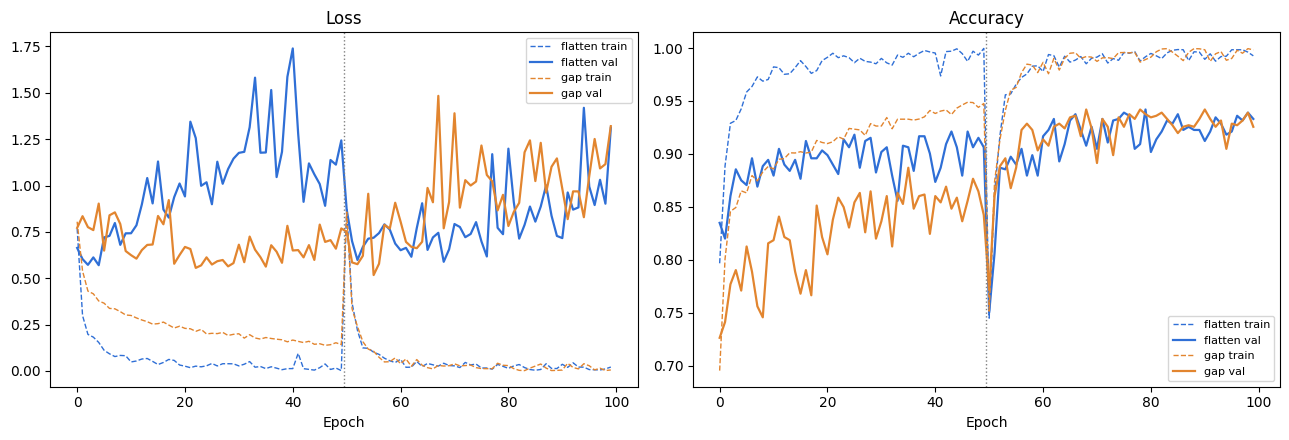

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for h, col in zip(HEADS, ["#2f6fd6", "#e2852f"]):
    H = RUNS[h]["hist"]
    ax[0].plot(H["loss"], c=col, ls="--", lw=1, label=f"{h} train"); ax[0].plot(H["val_loss"], c=col, lw=1.6, label=f"{h} val")
    ax[1].plot(H["accuracy"], c=col, ls="--", lw=1, label=f"{h} train"); ax[1].plot(H["val_accuracy"], c=col, lw=1.6, label=f"{h} val")
for a, t in zip(ax, ["Loss", "Accuracy"]):
    a.axvline(RUNS[HEADS[0]]["n1"] - 0.5, c="gray", ls=":", lw=1); a.set_title(t); a.set_xlabel("Epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RES / "fig_curves_compare.png", dpi=200); plt.show()

## 8. M5: confusion matrices

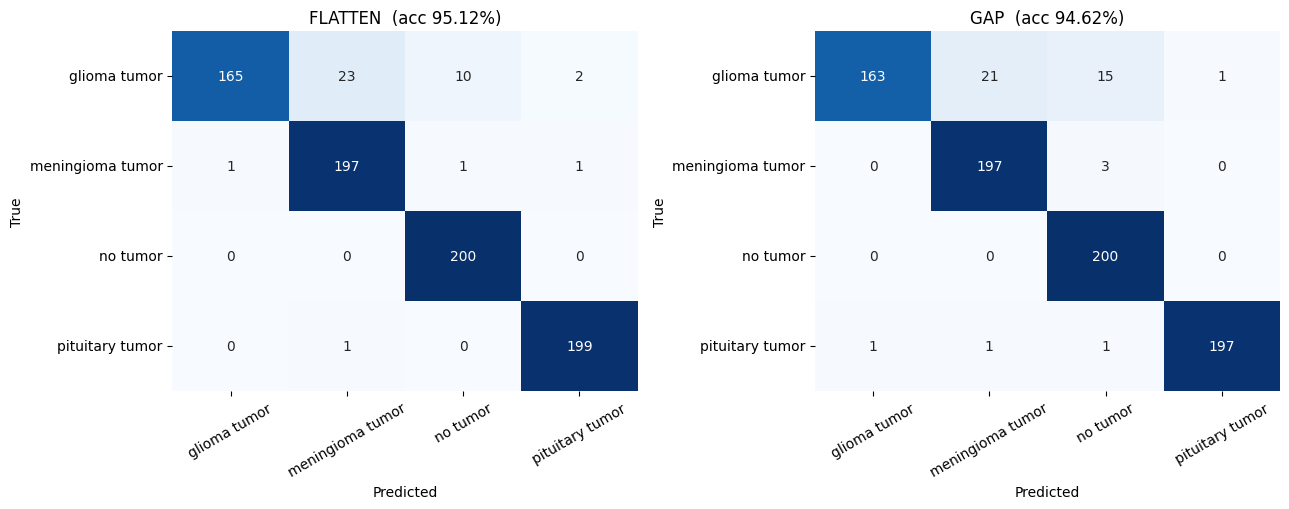


FLATTEN
                  precision    recall  f1-score   support

    glioma tumor     0.9940    0.8250    0.9016       200
meningioma tumor     0.8914    0.9850    0.9359       200
        no tumor     0.9479    1.0000    0.9732       200
 pituitary tumor     0.9851    0.9950    0.9900       200

        accuracy                         0.9513       800
       macro avg     0.9546    0.9513    0.9502       800
    weighted avg     0.9546    0.9513    0.9502       800


GAP
                  precision    recall  f1-score   support

    glioma tumor     0.9939    0.8150    0.8956       200
meningioma tumor     0.8995    0.9850    0.9403       200
        no tumor     0.9132    1.0000    0.9547       200
 pituitary tumor     0.9949    0.9850    0.9899       200

        accuracy                         0.9463       800
       macro avg     0.9504    0.9462    0.9451       800
    weighted avg     0.9504    0.9463    0.9451       800



In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for a, h in zip(ax, HEADS):
    sns.heatmap(CM[h], annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=NAMES, yticklabels=NAMES)
    a.set_title(f"{h.upper()}  (acc {M[h]['Test accuracy (%)']:.2f}%)"); a.set_xlabel("Predicted"); a.set_ylabel("True")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(RES / "fig_confusion_compare.png", dpi=200); plt.show()
for h in HEADS:
    print(f"\n{h.upper()}"); print(classification_report(RUNS[h]["y"], RUNS[h]["p"].argmax(1), target_names=NAMES, digits=4, zero_division=0))

## 9. M5: misclassified images (failure analysis)

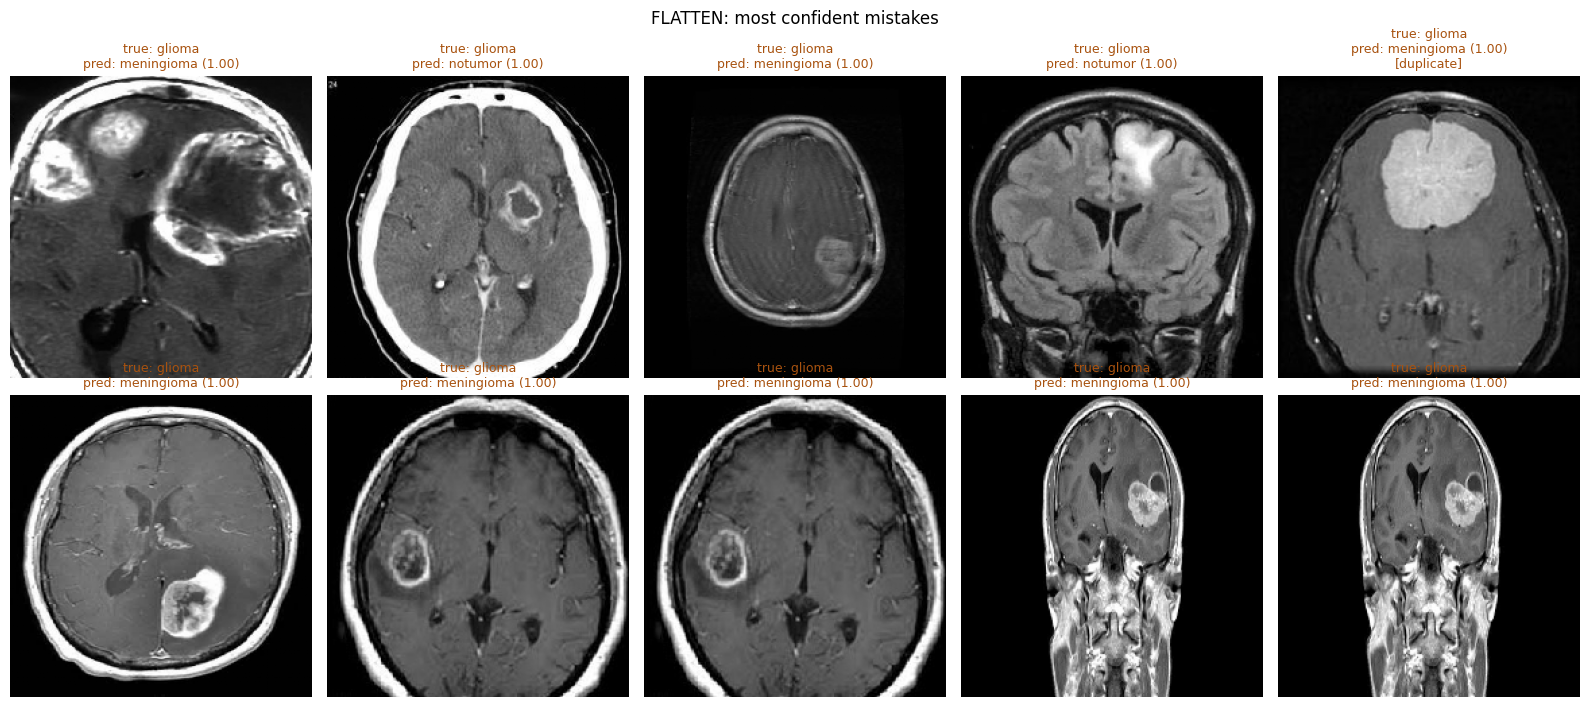

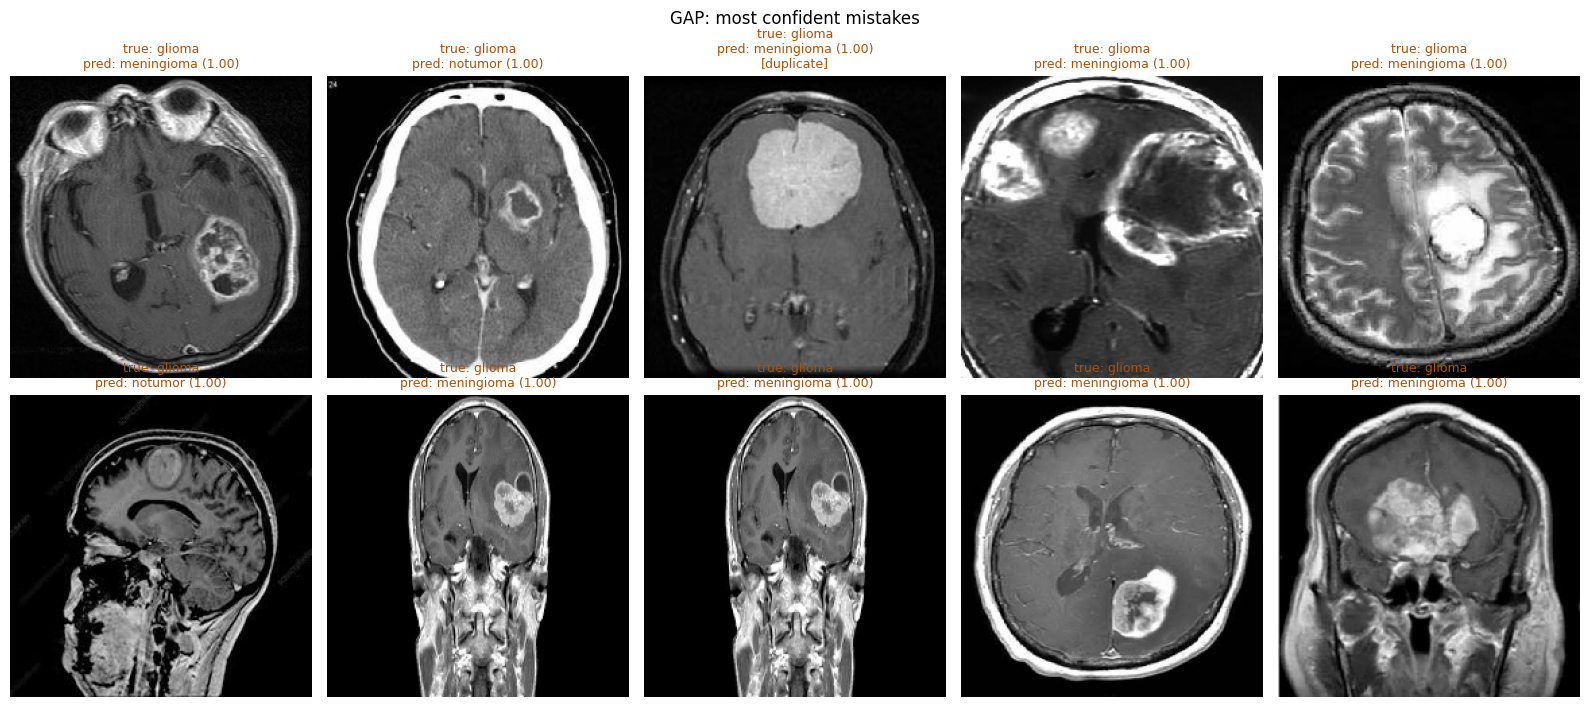

,model,true,predicted,count
0,flatten,glioma,meningioma,23
1,flatten,glioma,notumor,10
2,flatten,glioma,pituitary,2
3,flatten,meningioma,glioma,1
4,flatten,meningioma,notumor,1
5,flatten,meningioma,pituitary,1
6,flatten,pituitary,meningioma,1
7,gap,glioma,meningioma,21
8,gap,glioma,notumor,15
9,gap,glioma,pituitary,1


In [13]:
def show_errors(h, n=10):
    y, p, files = RUNS[h]["y"], RUNS[h]["p"], RUNS[h]["files"]
    wrong = np.where(p.argmax(1) != y)[0]
    wrong = wrong[np.argsort(-p[wrong].max(1))][:n]          # most confident mistakes first
    if len(wrong) == 0: print(h, ": no errors"); return
    cols = 5; rows = math.ceil(len(wrong) / cols)
    fig, ax = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows)); ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis("off")
    for a, i in zip(ax, wrong):
        a.imshow(Image.open(TEST_DIR / files[i]), cmap="gray")
        a.set_title(f"true: {CLASSES[y[i]]}\npred: {CLASSES[p[i].argmax()]} ({p[i].max():.2f})"
                    + ("\n[duplicate]" if DUP[i] else ""), fontsize=9, color="#a8520f")
    plt.suptitle(f"{h.upper()}: most confident mistakes"); plt.tight_layout()
    plt.savefig(RES / f"fig_misclassified_{h}.png", dpi=170); plt.show()
for h in HEADS: show_errors(h)

err = pd.DataFrame([{"model": h, "true": CLASSES[t], "predicted": CLASSES[q]}
                    for h in HEADS for t, q in zip(RUNS[h]["y"], RUNS[h]["p"].argmax(1)) if t != q])
err.groupby(["model", "true", "predicted"]).size().rename("count").reset_index()

## 10. M5: Grad-CAM — where does each model look?
Red areas drove the decision. A good model should focus on the tumor rather than the skull edges or the background.

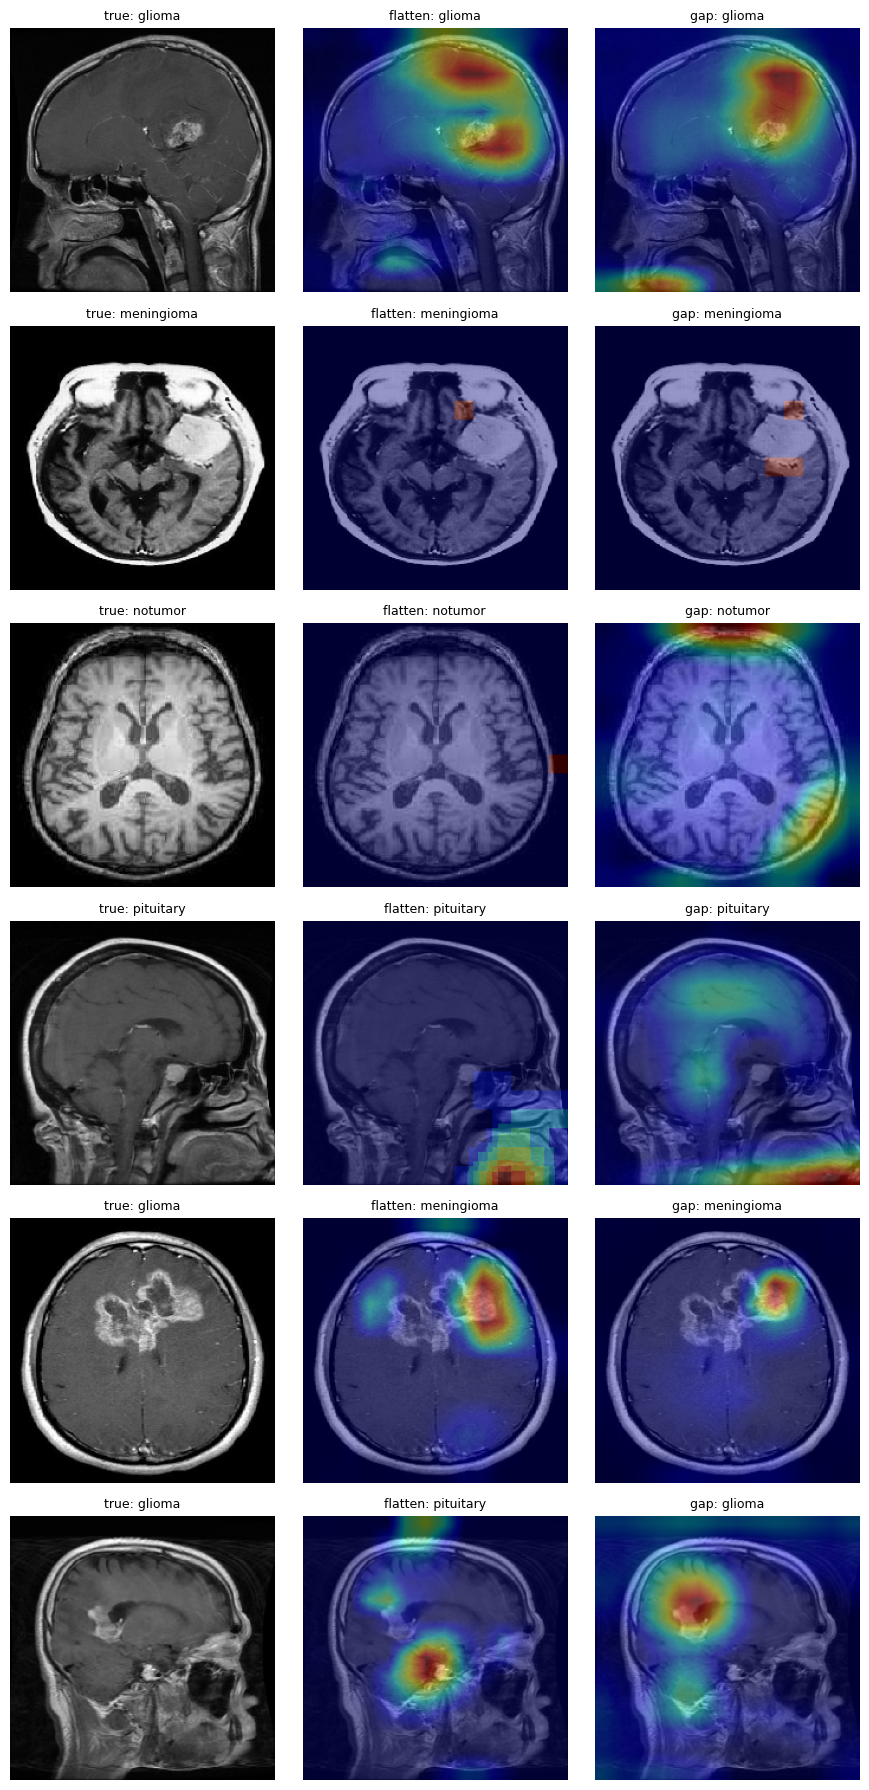

In [14]:
def gradcam(model, img_arr):
    base = model.layers[0]
    conv_model = keras.Model(base.inputs, [base.get_layer("block5_conv3").output, base.output])
    x = tf.convert_to_tensor(img_arr[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv, out = conv_model(x)
        tape.watch(conv)
        for l in model.layers[1:]:
            out = l(out)
        cls = int(tf.argmax(out[0])); score = out[:, cls]
    g = tape.gradient(score, conv)[0]; w = tf.reduce_mean(g, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * w, axis=-1)).numpy()
    cam = cam / (cam.max() + 1e-8)
    return np.array(Image.fromarray(np.uint8(cam * 255)).resize(IMG_SIZE, Image.BILINEAR)) / 255.0, cls

rs = np.random.RandomState(SEED)
pick = [int(rs.choice(np.where(RUNS["flatten"]["y"] == k)[0])) for k in range(len(CLASSES))]
wrong_g = np.where(RUNS["flatten"]["p"].argmax(1) != RUNS["flatten"]["y"])[0]
pick += [int(i) for i in wrong_g[:2]]
loaded = {h: keras.models.load_model(RES / f"model_{h}.keras") for h in HEADS}
fig, ax = plt.subplots(len(pick), 3, figsize=(9, 3 * len(pick)))
for r, i in enumerate(pick):
    f = RUNS["flatten"]["files"][i]
    gray = np.asarray(Image.open(TEST_DIR / f).convert("L").resize(IMG_SIZE), dtype=np.float32) / 255.0
    rgb = np.repeat(gray[..., None], 3, axis=-1)
    ax[r, 0].imshow(gray, cmap="gray"); ax[r, 0].set_title(f"true: {CLASSES[RUNS['flatten']['y'][i]]}", fontsize=9)
    for c, h in enumerate(HEADS, start=1):
        cam, cls = gradcam(loaded[h], rgb)
        ax[r, c].imshow(gray, cmap="gray"); ax[r, c].imshow(cam, cmap="jet", alpha=0.4)
        ax[r, c].set_title(f"{h}: {CLASSES[cls]}", fontsize=9)
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.savefig(RES / "fig_gradcam.png", dpi=170); plt.show()

## 11. Files to download (Output tab → `work/results/`)

In [15]:
for p in sorted(RES.iterdir()):
    print(f"{p.name:35s} {p.stat().st_size/1e6:8.2f} MB")

ablation_rows.tex                       0.00 MB
ablation_table.csv                      0.00 MB
fig_confusion_compare.png               0.11 MB
fig_curves_compare.png                  0.33 MB
fig_gradcam.png                         2.82 MB
fig_misclassified_flatten.png           1.27 MB
fig_misclassified_gap.png               1.52 MB
history_flatten.csv                     0.01 MB
history_gap.csv                         0.01 MB
model_flatten.keras                   239.87 MB
model_gap.keras                       164.37 MB
prediction_check.csv                    0.00 MB
preds_flatten.npz                       0.03 MB
preds_gap.npz                           0.03 MB
results_summary.json                    0.00 MB
